In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.metrics import accuracy_score

dimenssions de X:  (100, 2)
dimenssions de y:  (100, 1)


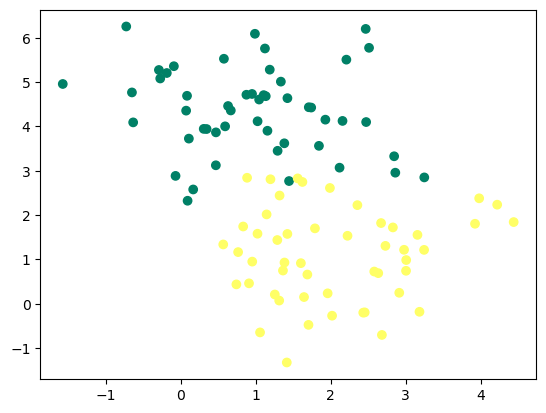

In [8]:
X, y = make_blobs(n_samples=100, n_features=2, centers=2, random_state=0)
y = y.reshape((y.shape[0], 1))

print('dimenssions de X: ', X.shape)
print('dimenssions de y: ', y.shape)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='summer')
plt.show()

In [9]:
def initialisation(X):
    W = np.random.randn(X.shape[1], 1)
    b = np.random.rand(1)
    return (W, b)

In [10]:
W, b = initialisation(X)
print('valeures de W1, w2 et b a l\'initialisation', W, b)

valeures de W1, w2 et b a l'initialisation [[-0.43297032]
 [ 2.10229218]] [0.31029648]


In [11]:
def model(X, W, b):
    Z = X.dot(W) + b
    A = 1 / (1 + np.exp(-Z))
    return A

In [12]:
A = model(X, W, b)
A.shape

(100, 1)

In [13]:
def log_loss(A, y):
    return 1 / len(y) * np.sum(-y * np.log(A) - (1 - y) * np.log(1 - A))

In [14]:
log_loss(A, y)

np.float64(4.752419452206467)

In [15]:
def gradients(A, X, y):
    dW = 1 / len(y) * np.dot(X.T, A - y)
    db = 1 / len(y) * np.sum(A - y)
    return (dW, db)

In [16]:
dW, db = gradients(A, X, y)
print('dW: ', dW, 'db: ', db)

dW:  [[0.19500196]
 [2.15955226]] db:  0.36502110391790327


In [17]:
def update(dW, db, W, b, learning_rate):
    W = W - learning_rate * dW
    b = b - learning_rate * db
    return (W, b)

In [18]:
def predict(X, W, b):
    A = model(X, W, b)
    return A>= 0.5

In [19]:
#Reseau de neurone proprement dit: 

def artificial_neuron(X, y, learning_rate = 0.1, n_iter = 100):
    #initialisation W, b
    W, b = initialisation(X)

    #tableau de l'evolution de Loss
    Loss_tab = []

    #Historique d'apprentissage

    for i in range(n_iter):
        A = model(X, W, b)
        Loss = log_loss(A, y)
        Loss_tab.append(Loss)
        dW, db = gradients(A, X, y)
        W, b = update(dW, db, W, b, learning_rate)

    y_pred = predict(X, W, b)
    print(accuracy_score(y, y_pred))

    plt.plot(Loss_tab)
    plt.show()

    return (W, b)

0.9


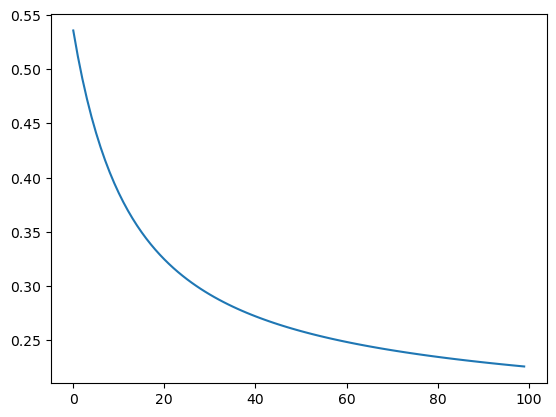

In [20]:
W, b = artificial_neuron(X, y)

In [21]:
W, b

(array([[ 1.08162089],
        [-1.05654532]]),
 array([0.80512513]))

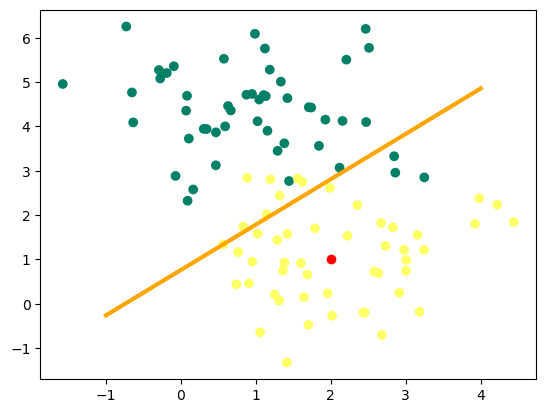

In [22]:
new_plant = np.array([2, 1])

x0 = np.linspace(-1, 4, 100)
x1 = ( -W[0] * x0 - b) / W[1]

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='summer')
plt.scatter(new_plant[0], new_plant[1], c='r')
plt.plot(x0, x1, c='orange', lw=3)
plt.show()

In [23]:
predict(new_plant, W, b)

array([ True])

In [24]:
import plotly.graph_objects as go

In [25]:
fig = go.Figure(data=[go.Scatter3d(x=X[:, 0], y=X[:, 1], z=y.flatten(), mode='markers', marker=dict(size=5, color=y.flatten(), colorscale='Y1Gn', opacity=0.8, reversescale=True))])

ValueError: 
    Invalid value of type 'builtins.str' received for the 'colorscale' property of scatter3d.marker
        Received value: 'Y1Gn'

    The 'colorscale' property is a colorscale and may be
    specified as:
      - A list of colors that will be spaced evenly to create the colorscale.
        Many predefined colorscale lists are included in the sequential, diverging,
        and cyclical modules in the plotly.colors package.
      - A list of 2-element lists where the first element is the
        normalized color level value (starting at 0 and ending at 1),
        and the second item is a valid color string.
        (e.g. [[0, 'green'], [0.5, 'red'], [1.0, 'rgb(0, 0, 255)']])
      - One of the following named colorscales:
            ['aggrnyl', 'agsunset', 'algae', 'amp', 'armyrose', 'balance',
             'blackbody', 'bluered', 'blues', 'blugrn', 'bluyl', 'brbg',
             'brwnyl', 'bugn', 'bupu', 'burg', 'burgyl', 'cividis', 'curl',
             'darkmint', 'deep

In [ ]:
fig.update_layout(template='plotly_dark', margin=dict(l=0, r=0, b=0, t=0))
fig.layout.scene.camera.projection.type = "orthographic"
fig.show()

In [ ]:
x0 = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
x1 = np.linspace(X[:, 1].min(), X[:, 1].max(), 100)
xx0, xx1 = np.meshgrid(x0, x1)
Z = W[0] * xx0 + W[1] * xx1 + b
A = 1 / (1 + np.exp(-Z))

fig = (go.Figure(data=[go.Surface(z=A, x=xx0, y=xx1, colorscale='YlGn', opacity=0.7, reversescale=True)]))
fig.add_scatter3d(x=X[:, 0], y=X[:, 1], z=y.flatten(), mode='markers', marker=dict(size=5, color=y.flatten(), colorscale='Y1Gn', opacity=0.9, reversescale=True))

fig.update_layout(template='plotly_dark', margin=dict(l=0, r=0, b=0, t=0))
fig.layout.scene.camera.projection.type = "orthographic"
fig.show()